# Problem
Recover the geometry and source/blend flux of the independently modeled 2010 stellar subevent in OGLE-2008-BLG-092. All 383 published OGLE-IV measurements are used. The earlier planetary and primary-star subevents belong to a different OGLE-III acquisition and are outside this bound problem. The 2014 paper explicitly uses a point-source point-lens model for this stellar subevent.

This notebook actively reconstructs the full measured curve with local mathematics. Independent physical truth is unavailable: the separately executed original MulensModel fit is a numerical reference. Neither a good fit nor agreement with this reference identifies the lens mass or distance.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data,flux_from_magnitude,magnitude_from_flux
from src.physics_model import magnification,predict,separation
from src.solvers import reconstruct,profile_objective,fit_fluxes,INITIAL
from src.visualization import comparison_figure
data=load_data()
with np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f:upstream={k:f[k] for k in f.files}
review=Path(os.environ.get('IMAGING_REVIEW_DIR',str(root.parent.parent/'archive/review')));review.mkdir(parents=True,exist_ok=True)


# Data
The 1.3 m Warsaw Telescope at Las Campanas measured this source in I band with the 32-chip OGLE-IV CCD camera. Difference-image photometry yields the supplied magnitudes. The published acquisition contains exactly 383 epochs; its error bars were set to the baseline dispersion, 0.0068 mag. These are author-processed measured observations, not synthesized model values. Time is heliocentric Julian date minus 2450000, in days.

Magnitude-to-flux conversion uses an arbitrary but explicit zero point of magnitude 22. This choice sets units and does not calibrate the intrinsic stellar luminosity. No row filtering or additional error rescaling is performed.

In [2]:
flux,error=flux_from_magnitude(data['magnitude'],data['magnitude_error'])
print('Epochs:',len(flux),'time range:',data['time'].min(),data['time'].max())
print('Magnitude uncertainty range:',data['magnitude_error'].min(),data['magnitude_error'].max())
print('Public inputs:',{k:v.shape for k,v in data.items()})


Epochs: 383 time range: 5264.841 5861.52181
Magnitude uncertainty range: 0.0068 0.0068
Public inputs: {'time': (383,), 'magnitude': (383,), 'magnitude_error': (383,)}


# Physics
For closest approach time $t_0$, dimensionless impact parameter $u_0$, and Einstein crossing time $t_E$, rectilinear separation and total magnification are
$$u(t)=\sqrt{u_0^2+[(t-t_0)/t_E]^2},\qquad A(u)=\frac{u^2+2}{u\sqrt{u^2+4}}.$$
The two unresolved gravitationally lensed images contribute the total observed flux
$$F(t)=F_s A[u(t)]+F_b.$$
Here $F_s$ is unlensed source flux and $F_b$ is constant blend flux from unresolved neighbors/background. Both use the flux of magnitude 22 as one unit. The two trajectory reflections have identical magnification, so we report positive $u_0$. The dimensional Einstein radius and relative proper motion are not separately measured by these data.

For measured magnitude $m$ and error $\sigma_m$, the flux conversion and propagated error are
$$F=10^{0.4(22-m)},\qquad \sigma_F=0.4\ln(10)F\sigma_m.$$
This assumes small magnitude errors. The supplied errors are empirical baseline scatter, so residuals test this simplified noise description.

# Method
At every trial geometry, form a design matrix with columns $A(t)$ and 1. Divide each row and observed flux by its uncertainty, and solve the two-column weighted least-squares system for source and blend flux. This eliminates the linear nuisance parameters exactly. Minimize
$$\chi^2=\sum_i[(F_i-F_sA_i-F_b)/\sigma_i]^2$$
over the remaining three geometric parameters using the original example's Nelder-Mead search, initialized at $(5380,0.5,25)$. There is no regularizer or extra uncertainty inflation. The full model has five fitted parameters, hence 378 residual degrees of freedom. The source implementation retains the original numerical conventions; independent fixtures verify conversion, magnification, weighted projection and final parameters.

In [3]:
started=time.perf_counter();result,details=reconstruct(data);seconds=time.perf_counter()-started
p=result['reconstruction'][0];coeff=result['source_blend_flux'][0]
np.savez('output/reconstruction.npz',**result)
import importlib.util
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k] for k in f.files}
metrics=judge.score(result,reference,{k:v[None] for k,v in data.items()})
print('Fresh runtime [s]:',seconds,'fresh metrics:',json.dumps(metrics,indent=2))


Fresh runtime [s]: 0.0062945999670773745 fresh metrics: {
  "t0_error": 0.0,
  "u0_error": 0.0,
  "tE_error": 0.0,
  "flux_error": 2.832022932595607e-16,
  "reduced_chi2": 1.1301688410786792
}


# Results
The historical paper's Table 1 reports the secondary subevent, not independent truth. Below it is distinguished from this task's original-code run and fresh local reconstruction. The reference metric applies to the fresh output; historical rounded values are shown only for scientific context.

| Quantity | Historical paper | Original run | Fresh local |
|---|---:|---:|---:|
| t0 [day] | 5379.571 | 5379.57091303 | 5379.57091303 |
| u0 [Einstein radius] | 0.523 | 0.522979273229 | 0.522979273229 |
| tE [day] | 17.94 | 17.9400199587 | 17.9400199587 |
| blend/source | 0.016 | 0.0162900004479 | 0.0162900004479 |
| chi-square | 427.2 | 427.203821928 | 427.203821928 |

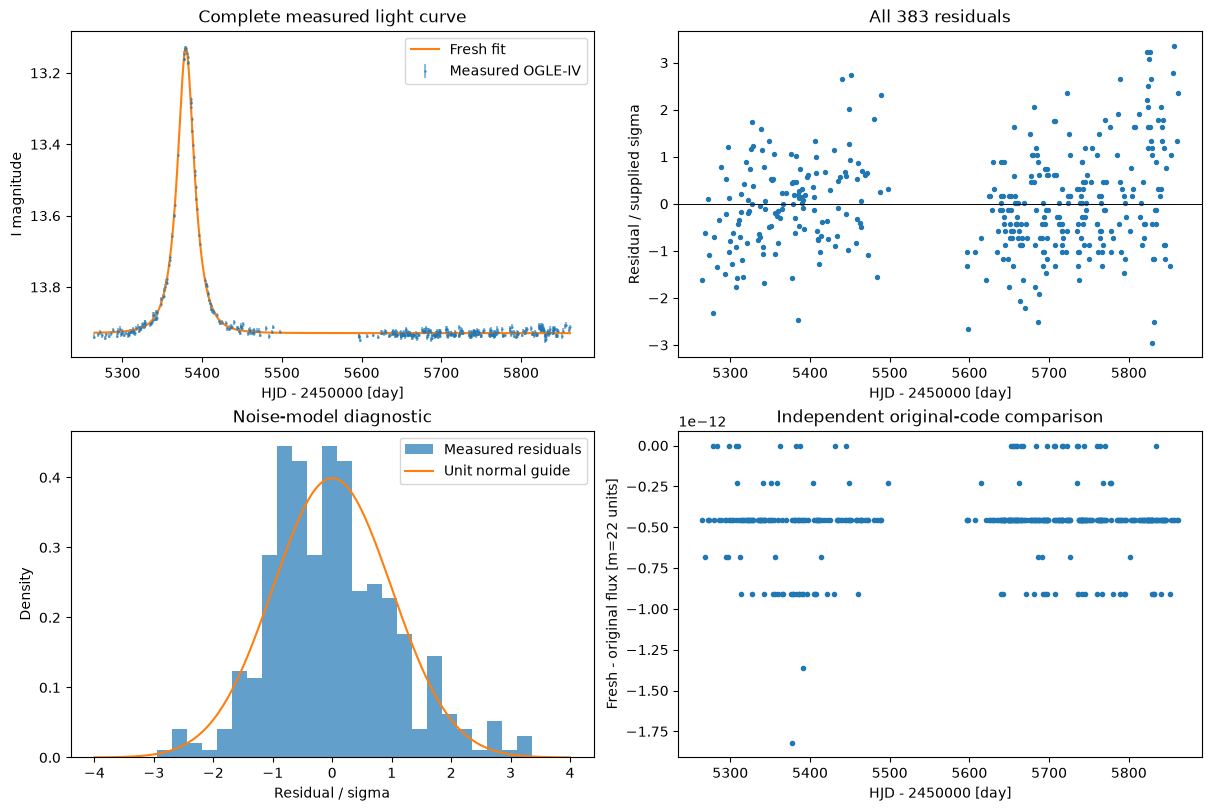

In [4]:
rows=[('t0 [day]',5379.571,upstream['parameters'][0],p[0]),('u0 [Einstein radius]',.523,upstream['parameters'][1],p[1]),('tE [day]',17.94,upstream['parameters'][2],p[2]),('blend/source',.016,upstream['fluxes'][1]/upstream['fluxes'][0],coeff[1]/coeff[0]),('chi-square',427.2,float(upstream['chi2']),details['chi2'])]
table='| Quantity | Historical paper | Original run | Fresh local |'+chr(10)+'|---|---:|---:|---:|'+chr(10)
table+=chr(10).join(f'| {name} | {h:.8g} | {u:.12g} | {v:.12g} |' for name,h,u,v in rows)
display(Markdown(table))
fig=comparison_figure(data,result,details,upstream);fig.savefig(review/'mulens_comparison.png',dpi=150);plt.show()


A free blend term is weakly constrained by the event shape. The next comparisons are freshly computed: an otherwise identical fit with blend fixed to zero, a constant-flux null hypothesis, and the original initial geometry with its own fitted linear fluxes. The landscape profiles out both flux coefficients at each point; it fixes closest approach to the fresh optimum to expose the impact/timescale correlation. These are diagnostics, not replacements for the benchmark method.

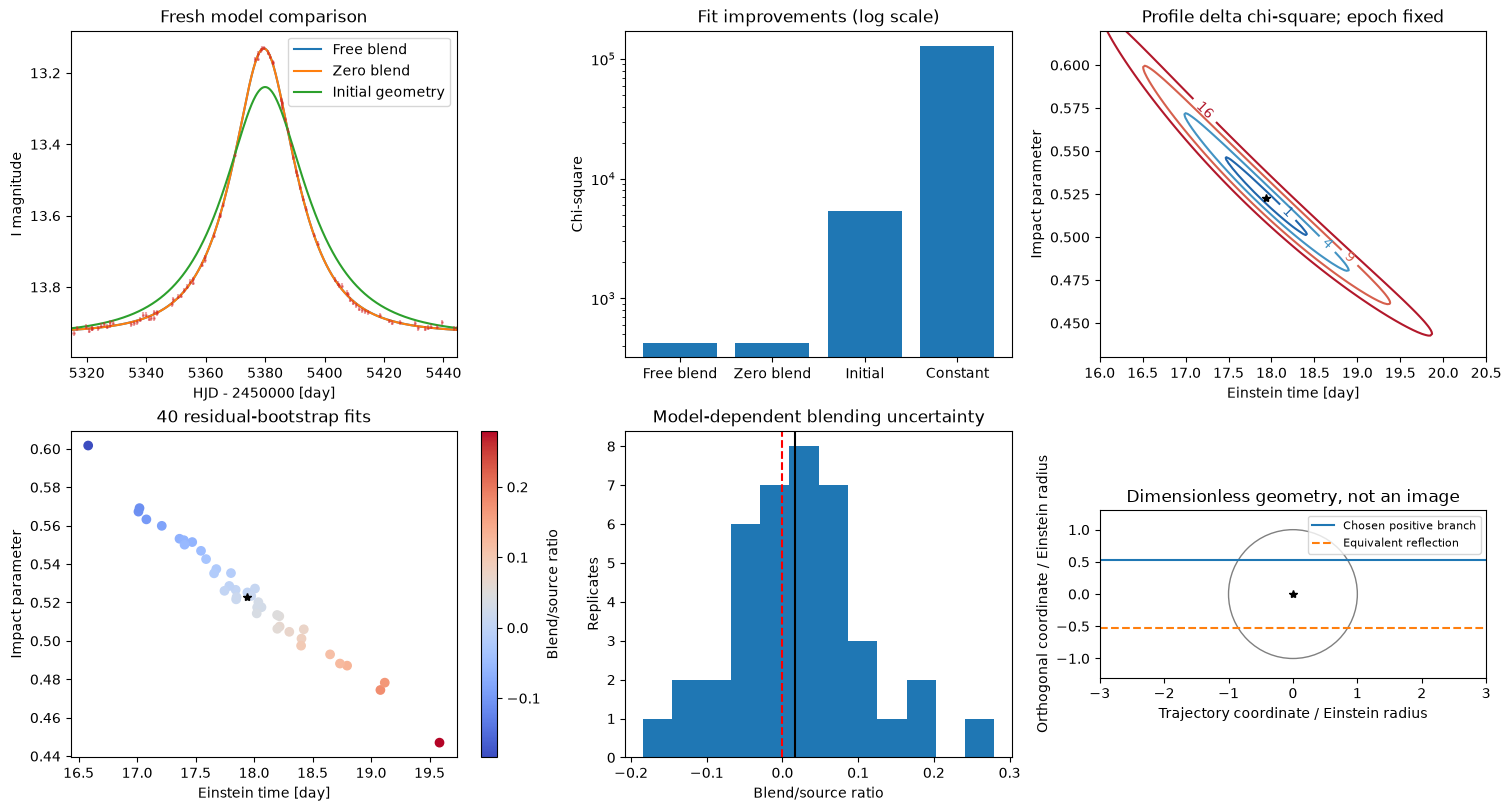

Fresh zero-blend chi-square: 427.25305661157864 constant chi-square: 129490.31922550473
Bootstrap SD [t0,u0,tE,source,blend]: [4.66709992e-02 2.96317601e-02 6.17195869e-01 1.44115484e+02
 1.43984879e+02]


422

In [5]:
zero,zd=reconstruct(data,blend=False)
constant=np.sum(flux/error**2)/np.sum(1/error**2);nullchi=np.sum(((flux-constant)/error)**2)
ia=magnification(data['time'],INITIAL);ic,im=fit_fluxes(ia,flux,error)
uvalues=np.linspace(.43,.62,181);evalues=np.linspace(16,20.5,181)
landscape=np.array([[profile_objective([p[0],u,e],data['time'],flux,error) for e in evalues] for u in uvalues])
rng=np.random.default_rng(4821);samples=[]
# Supplementary residual bootstrap: resamples measured standardized residuals.
# This is not a replacement acquisition or an independently calibrated confidence interval.
residual=(flux-details['model'])/error;residual-=residual.mean()
for _ in range(40):
    fb=details['model']+error*rng.choice(residual,len(residual),replace=True)
    bootstrap=dict(data);bootstrap['magnitude']=magnitude_from_flux(fb)
    # Preserve the original flux-error weights under the magnitude representation.
    bootstrap['magnitude_error']=error/(fb*np.log(10.)*.4)
    br,_=reconstruct(bootstrap,initial=p);samples.append(np.r_[br['reconstruction'][0],br['source_blend_flux'][0]])
samples=np.array(samples)
fig,ax=plt.subplots(2,3,figsize=(15,8),layout='constrained')
grid=np.linspace(p[0]-65,p[0]+65,1000)
for label,params,fs in [('Free blend',p,coeff),('Zero blend',zero['reconstruction'][0],zero['source_blend_flux'][0]),('Initial geometry',INITIAL,ic)]:ax[0,0].plot(grid,magnitude_from_flux(predict(grid,params,fs)),label=label)
ax[0,0].errorbar(data['time'],data['magnitude'],data['magnitude_error'],fmt='.',ms=2,alpha=.4);ax[0,0].set_xlim(grid.min(),grid.max());ax[0,0].invert_yaxis();ax[0,0].set(xlabel='HJD - 2450000 [day]',ylabel='I magnitude',title='Fresh model comparison');ax[0,0].legend()
ax[0,1].bar(['Free blend','Zero blend','Initial','Constant'],[details['chi2'],zd['chi2'],np.sum(((flux-im)/error)**2),nullchi]);ax[0,1].set(yscale='log',ylabel='Chi-square',title='Fit improvements (log scale)')
cs=ax[0,2].contour(evalues,uvalues,landscape-details['chi2'],levels=[1,4,9,16],colors=['#2166ac','#4393c3','#d6604d','#b2182b']);ax[0,2].clabel(cs);ax[0,2].plot(p[2],p[1],'k*');ax[0,2].set(xlabel='Einstein time [day]',ylabel='Impact parameter',title='Profile delta chi-square; epoch fixed')
sc=ax[1,0].scatter(samples[:,2],samples[:,1],c=samples[:,4]/samples[:,3],cmap='coolwarm');fig.colorbar(sc,ax=ax[1,0],label='Blend/source ratio');ax[1,0].plot(p[2],p[1],'k*');ax[1,0].set(xlabel='Einstein time [day]',ylabel='Impact parameter',title='40 residual-bootstrap fits')
ax[1,1].hist(samples[:,4]/samples[:,3],bins=12);ax[1,1].axvline(coeff[1]/coeff[0],color='k');ax[1,1].axvline(0,color='r',ls='--');ax[1,1].set(xlabel='Blend/source ratio',ylabel='Replicates',title='Model-dependent blending uncertainty')
tau=np.linspace(-3,3,500);ax[1,2].plot(tau,np.full_like(tau,p[1]),label='Chosen positive branch');ax[1,2].plot(tau,np.full_like(tau,-p[1]),'--',label='Equivalent reflection');circle=plt.Circle((0,0),1,fill=False,color='gray');ax[1,2].add_patch(circle);ax[1,2].plot(0,0,'k*');ax[1,2].set(xlim=(-3,3),ylim=(-1.3,1.3),aspect='equal',xlabel='Trajectory coordinate / Einstein radius',ylabel='Orthogonal coordinate / Einstein radius',title='Dimensionless geometry, not an image');ax[1,2].legend(fontsize=8)
fig.savefig(review/'mulens_diagnostics.png',dpi=150);plt.show()
print('Fresh zero-blend chi-square:',zd['chi2'],'constant chi-square:',nullchi)
print('Bootstrap SD [t0,u0,tE,source,blend]:',samples.std(axis=0,ddof=1))
(review/'mulens_notebook_measurements.json').write_text(json.dumps({'seconds':seconds,'metrics':metrics,'zero_blend_chi2':zd['chi2'],'null_chi2':float(nullchi),'bootstrap_sd':samples.std(axis=0,ddof=1).tolist()},indent=2),encoding='utf8')


# Conclusion
The complete measured OGLE-IV subevent is reproduced by explicit local point-lens mathematics and agrees with the independent original-code fit. The residual and chi-square comparisons test the acquisition model separately from numerical parity. The zero-blend comparison and residual bootstrap reveal that small blend flux is not a precise measurement of a companion's luminosity.

The trajectory reflection is unobservable and is fixed by convention. Finite-source size, parallax, absolute Einstein radius, lens mass and distance are not inferred here. Bootstrap scatter is conditional on the selected model and resampling assumption; the 40 replicates are a diagnostic rather than a calibrated posterior. The earlier planetary anomalies are neither synthesized nor silently folded into this stellar-sub-event task.